# Coembedding

Coembedding brings reactant and product structures into a shared coordinate frame while retaining each endpoint's molecular geometry and chemical identity. The resulting overlap is useful for constructing transition-state (TS) guesses.

In this notebook, `rx.coembed(reactant, product)` takes RDKit molecules parsed from atom-mapped SMILES. The endpoints must contain matching atom inventories with preserved input atom orders.

The algorithm first compares the mapped graphs. Changes in bonded neighborhoods, formal charges, and declared stereochemistry identify TS-partaking atoms. Unchanged heavy atoms and unchanged explicitly mapped hydrogens form the default spectator alignment. `ts_atoms=` can be used to specify additional atoms partaking in the TS.

An initial embedding of the endpoint $E_1$ with the most graph bonds is chosen. Ties prefer fewer haptic centroid helpers, then the reactant. RDKit distance geometry generates this endpoint under its own chemistry constraints, followed by restrained UFF relaxation. Its mapped coordinates are copied directly to the other endpoint $E_2$. 

$$
\mathbf r_i^{E_1}\longrightarrow\mathbf r_j^{E_2},
$$

Choosing the endpoint with the most graph bonds as the starting point is preferable as the less bonded endpoint is likely to allow for more flexibility, aiding convergence and stability.
The copied endpoint is then repaired and relaxed using its own bond graph and constraints. A changed atropisomeric hand is seeded by rotating the attached group with RDKit's dihedral transformation; haptic centroid helpers are rebuilt independently for each endpoint, and stereoisomerism is verified to match that given in the input.

For optimization, let $R=\{\mathbf r_i\}$ and $P=\{\mathbf p_j\}$ denote the reactant and product coordinates. We minimize the joint objective

$$
J(R,P)=E_R(R)+E_P(P)
+\frac{w_S}{|S|}\sum_{(i,j)\in S}
\left[\!\|\mathbf r_i-\mathbf p_j\|\right]^2
+\frac{w_T}{|T|}\sum_{(i,j)\in T}
\left[\max\!\left(\|\mathbf r_i-\mathbf p_j\|-b_{ij},0\right)\right]^2.
$$

Here, $E_R$ and $E_P$ contain each endpoint's UFF energy and additional chemistry restraints, such as coordination geometry, planarity, and requested noncovalent contacts. $S$ and $T$ are the spectator and TS atom-pair sets. The default weights are $w_S=25$ (`alignment_weight`) and $w_T=1.25$ (`ts_weight`). Spectators have a larger weight because they should remain closely aligned; the smaller TS weight allows more reaction-related motion.

TS pairs have a flat-bottom allowance $b_{ij}$, inferred from the largest incompatible RDKit distance-window gap involving that mapped atom. Displacement within the allowance is unpenalized; excess is penalized quadratically. Spectator pairs have zero allowance.

Before initiating the optimization procedure, RDKit rigidly fits the product onto the reactant using spectator atoms. The fit is retained only if the complete coupling penalty, including TS atoms, does not increase.

The joint objective is then minimized by alternating endpoint updates:

1. Hold the product coordinates fixed. Add positional restraints centered on those coordinates to the reactant's UFF field, using the displacement tolerances and coupling strengths above.
2. Starting from the current reactant geometry, run up to 100 native RDKit optimizer steps. Recalculate the full joint objective and accept the update if it does not increase beyond numerical tolerance.
3. Hold the updated reactant fixed and perform the corresponding product update.
4. Repeat until the joint gradient is sufficiently small, a complete cycle makes only a small energy improvement, the iteration budget is exhausted, or an update cannot advance the objective. An energy-increasing update is reverted and that coupled pass stops.

Both endpoints are checked for structural validity and stereochemistry. Explicit graph stereo remains part of the molecular identity. For XYZ inputs, use `stereo="all"` to preserve measured stereochemistry; `stereo="free"` disables that preservation filter.

Fresh shared seeds are used only in bounded recovery for missing or rejected pairs, with successful pairs retained.

In [1]:
from pathlib import Path

import rxembed as rx
import xyzrender
from IPython.display import display


## SN2 reaction

Methyl iodide undergoes an SN2 substitution with a cyclic amine, forming a C–N bond as the C–I bond breaks. The larger substrate shows how coembedding handles a reaction center surrounded by a substantial spectator framework.


Reactant: [C:1]([I:2])([H:3])([H:4])[H:5].[C:6]([c:7]1[c:8]([B:9]2[O:10][C:11]([C:12]([H:29])([H:30])[H:31])([C:13]([H:32])([H:33])[H:34])[C:14]([C:15]([H:35])([H:36])[H:37])([C:16]([H:38])([H:39])[H:40])[O:17]2)[c:18]([H:41])[c:19]([H:42])[c:20]2[c:21]1[N:22]([H:43])[C:23]([H:44])([H:45])[C:24]([H:46])([H:47])[O:25]2)([H:26])([H:27])[H:28]
Product:  [C:1]([H:3])([H:4])([H:5])[N@+:22]1([H:43])[c:21]2[c:7]([C:6]([H:26])([H:27])[H:28])[c:8]([B:9]3[O:10][C:11]([C:12]([H:29])([H:30])[H:31])([C:13]([H:32])([H:33])[H:34])[C:14]([C:15]([H:35])([H:36])[H:37])([C:16]([H:38])([H:39])[H:40])[O:17]3)[c:18]([H:41])[c:19]([H:42])[c:20]2[O:25][C:24]([H:46])([H:47])[C:23]1([H:44])[H:45].[I-:2]


1/47 atoms have no bonds from file connectivity — use --rebuild to re-detect with xyzgraph


Accepted pairs: 1


GIFResult(path=PosixPath('/tmp/tmpel4wuw6k.gif'))
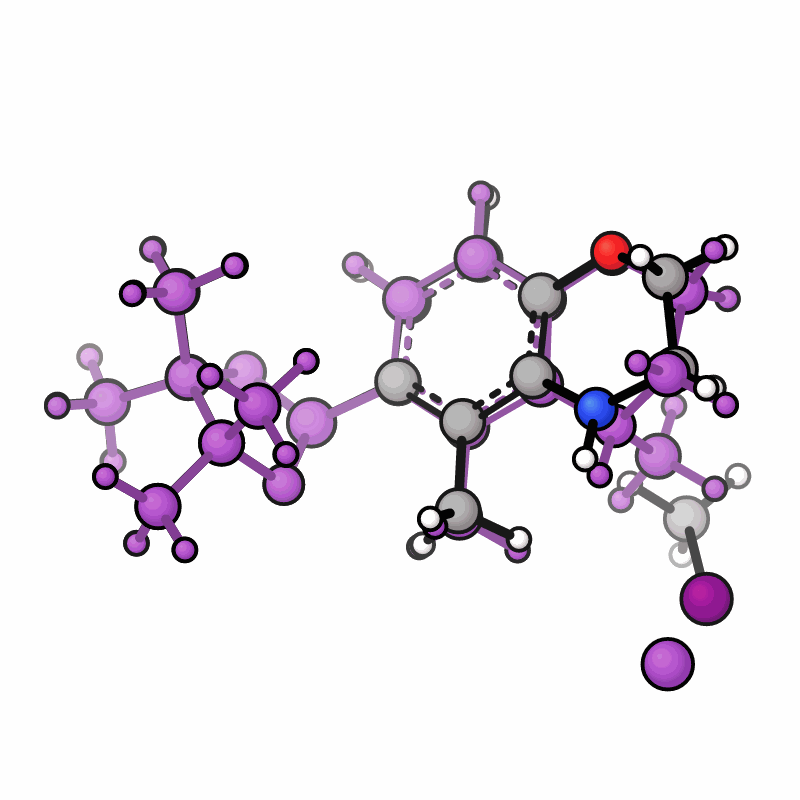

In [2]:
sn2_reactant_smiles = """[C:1]([I:2])([H:3])([H:4])[H:5].[C:6]([c:7]1[c:8]([B:9]2[O:10][C:11]([C:12]([H:29])([H:30])[H:31])([C:13]([H:32])([H:33])[H:34])[C:14]([C:15]([H:35])([H:36])[H:37])([C:16]([H:38])([H:39])[H:40])[O:17]2)[c:18]([H:41])[c:19]([H:42])[c:20]2[c:21]1[N:22]([H:43])[C:23]([H:44])([H:45])[C:24]([H:46])([H:47])[O:25]2)([H:26])([H:27])[H:28]"""
sn2_product_smiles = """[C:1]([H:3])([H:4])([H:5])[N@+:22]1([H:43])[c:21]2[c:7]([C:6]([H:26])([H:27])[H:28])[c:8]([B:9]3[O:10][C:11]([C:12]([H:29])([H:30])[H:31])([C:13]([H:32])([H:33])[H:34])[C:14]([C:15]([H:35])([H:36])[H:37])([C:16]([H:38])([H:39])[H:40])[O:17]3)[c:18]([H:41])[c:19]([H:42])[c:20]2[O:25][C:24]([H:46])([H:47])[C:23]1([H:44])[H:45].[I-:2]"""
print(f"Reactant: {sn2_reactant_smiles}\nProduct:  {sn2_product_smiles}")

sn2_reactant = rx.parse_smiles(sn2_reactant_smiles, remove_hs=False)
sn2_product = rx.parse_smiles(sn2_product_smiles, remove_hs=False)
sn2_pair = rx.coembed(
    sn2_reactant,
    sn2_product,
    n=1,
    seed=1,
    charge=0,
)
print(f"Accepted pairs: {len(sn2_pair)}")

sn2_reactant_mol, sn2_product_mol = sn2_pair[0]
sn2_reactant_scene = xyzrender.load(sn2_reactant_mol)
sn2_product_scene = xyzrender.load(sn2_product_mol)
display(
    xyzrender.render_gif(
        sn2_reactant_scene,
        gif_rot=True,
        overlay=sn2_product_scene,
        auto_align=False,
        rot_frames=36,
        gif_fps=8,
        hy=True,
    )
)


## Nazarov cyclization

These XYZ structures show a chiral dithiophosphoric acid–substrate complex for a Nazarov cyclization. The reaction is a conrotatory 4π electrocyclization of a divinyl ketone that forms a cyclopentenone framework and two stereogenic centers.


Accepted pairs: 1


GIFResult(path=PosixPath('/tmp/tmp0dfw7ruv.gif'))
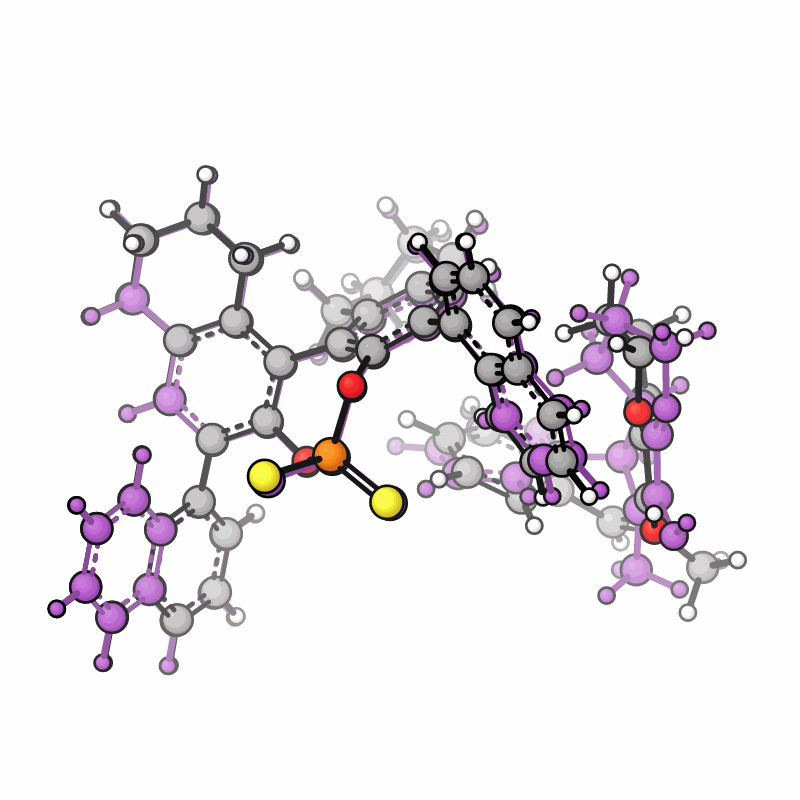

In [3]:
path_start = "structures/nazarov_start.xyz"
path_end = "structures/nazarov_end.xyz"

nazarov_pair = rx.coembed(
    path_start,
    path_end,
    n=1,
    seed=1,
    charge=0,
)
print(f"Accepted pairs: {len(nazarov_pair)}")

nazarov_reactant_mol, nazarov_product_mol = nazarov_pair[0]
nazarov_reactant_scene = xyzrender.load(nazarov_reactant_mol)
nazarov_product_scene = xyzrender.load(nazarov_product_mol)
display(
    xyzrender.render_gif(
        nazarov_reactant_scene,
        gif_rot=True,
        overlay=nazarov_product_scene,
        auto_align=False,
        rot_frames=36,
        gif_fps=8,
        hy=True,
    )
)


## Hydrogen bond and C–H···π contact

For this example, hold one hydrogen bond and one C–H···π contact during coembedding. xyzrender's NCI detection is enabled in the rotating overlay to show the resulting non-covalent contacts. rxembed exposes C–H···π restraints, but not a separate ring–ring π-stacking restraint.


Holding hydrogen bond: HB:N1->O147
Holding C–H···π contact: CHPI:H56->ring94
Accepted pairs: 1


GIFResult(path=PosixPath('/tmp/tmpadfu57j2.gif'))
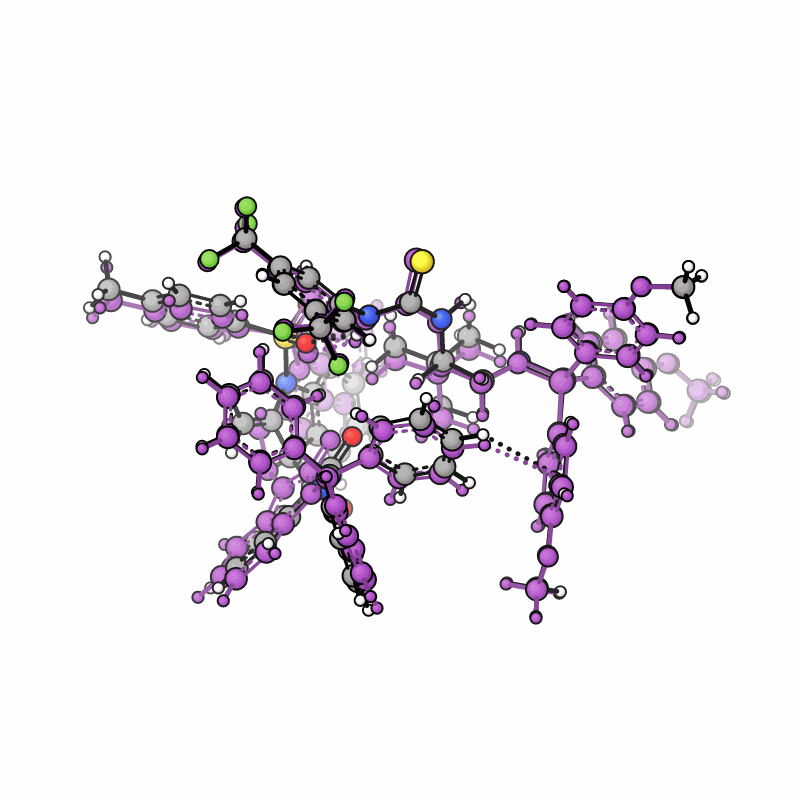

In [6]:
bimp_reactant_smiles = """[H:84][N:85]([C:86]([N:88]([C@@:92]([C:98]([N+:104]([H:117])=[P:118]([c:128]1[c:131]([H:138])[c:137]([H:150])[c:149]([O:158][C:161]([H:164])([H:165])[H:166])[c:139]([H:151])[c:132]1[H:140])([c:129]1[c:133]([H:142])[c:141]([H:153])[c:152]([O:159][C:162]([H:167])([H:168])[H:169])[c:143]([H:154])[c:134]1[H:144])[c:130]1[c:135]([H:146])[c:145]([H:156])[c:155]([O:160][C:163]([H:170])([H:171])[H:172])[c:147]([H:157])[c:136]1[H:148])([H:105])[H:106])([H:99])[C:100]([C:107]([H:119])([H:120])[H:121])([C:108]([H:122])([H:123])[H:124])[C:109]([H:125])([H:126])[H:127])[H:93])=[S:89])[c:87]1[c:90]([H:95])[c:94]([C:101]([F:110])([F:111])[F:112])[c:102]([H:113])[c:96]([C:103]([F:114])([F:115])[F:116])[c:91]1[H:97].[O:1]=[C:2]1[N:3]([C:4]([c:37]2[c:38]([H:41])[c:40]([H:45])[c:44]([H:47])[c:42]([H:46])[c:39]2[H:43])([c:48]2[c:49]([H:52])[c:51]([H:56])[c:55]([H:58])[c:53]([H:57])[c:50]2[H:54])[c:59]2[c:60]([H:63])[c:62]([H:67])[c:66]([H:69])[c:64]([H:68])[c:61]2[H:65])[c:5]2[c:6]([H:22])[c:7]([H:23])[c:8]([H:24])[c:9]([H:25])[c:10]2[C@@:11]1([O-:12])[C@@:15]1([H:33])[C:14](=[C:13]([H:30])[H:31])[N:32]([S:34](=[O:35])(=[O:36])[c:70]2[c:71]([H:74])[c:73]([H:78])[c:77]([C:80]([H:81])([H:82])[H:83])[c:75]([H:79])[c:72]2[H:76])[c:17]2[c:16]1[c:21]([H:29])[c:20]([H:28])[c:19]([H:27])[c:18]2[H:26]"""
bimp_product_smiles = """[H:84][N:85]([C:86]([N:88]([C@@:92]([C:98]([N+:104]([H:117])=[P:118]([c:128]1[c:131]([H:138])[c:137]([H:150])[c:149]([O:158][C:161]([H:164])([H:165])[H:166])[c:139]([H:151])[c:132]1[H:140])([c:129]1[c:133]([H:142])[c:141]([H:153])[c:152]([O:159][C:162]([H:167])([H:168])[H:169])[c:143]([H:154])[c:134]1[H:144])[c:130]1[c:135]([H:146])[c:145]([H:156])[c:155]([O:160][C:163]([H:170])([H:171])[H:172])[c:147]([H:157])[c:136]1[H:148])([H:105])[H:106])([H:99])[C:100]([C:107]([H:119])([H:120])[H:121])([C:108]([H:122])([H:123])[H:124])[C:109]([H:125])([H:126])[H:127])[H:93])=[S:89])[c:87]1[c:90]([H:95])[c:94]([C:101]([F:110])([F:111])[F:112])[c:102]([H:113])[c:96]([C:103]([F:114])([F:115])[F:116])[c:91]1[H:97].[O:1]=[c:2]1[n:3]([C:4]([c:37]2[c:38]([H:41])[c:40]([H:45])[c:44]([H:47])[c:42]([H:46])[c:39]2[H:43])([c:48]2[c:49]([H:52])[c:51]([H:56])[c:55]([H:58])[c:53]([H:57])[c:50]2[H:54])[c:59]2[c:60]([H:63])[c:62]([H:67])[c:66]([H:69])[c:64]([H:68])[c:61]2[H:65])[c:5]2[c:6]([H:22])[c:7]([H:23])[c:8]([H:24])[c:9]([H:25])[c:10]2[c-:11]1[O:12][C:13]([c:14]1[c:15]([H:33])[c:16]2[c:17]([c:18]([H:26])[c:19]([H:27])[c:20]([H:28])[c:21]2[H:29])[n:32]1[S:34](=[O:35])(=[O:36])[c:70]1[c:71]([H:74])[c:73]([H:78])[c:77]([C:80]([H:81])([H:82])[H:83])[c:75]([H:79])[c:72]1[H:76])([H:30])[H:31]"""
bimp_reactant = rx.parse_smiles(bimp_reactant_smiles, remove_hs=False)
bimp_product = rx.parse_smiles(bimp_product_smiles, remove_hs=False)

nci_candidates = rx.nci_candidates(bimp_reactant)
hb_label, hb_contact = next(
    ((label, contact) for label, contact in nci_candidates.items() if label.startswith("HB:")),
    (None, None),
)
pi_label, pi_contact = next(
    ((label, contact) for label, contact in nci_candidates.items() if label.startswith("CHPI:")),
    (None, None),
)
if hb_contact is None or pi_contact is None:
    raise RuntimeError("Could not find both an HB and a C–H···π contact for bimp")
print(f"Holding hydrogen bond: {hb_label}")
print(f"Holding C–H···π contact: {pi_label}")

bimp_pair = rx.coembed(
    bimp_reactant,
    bimp_product,
    n=1,
    seed=42,
    charge=0,
    stereo="free",
    contacts=[hb_contact, pi_contact],
)
print(f"Accepted pairs: {len(bimp_pair)}")

bimp_reactant_mol, bimp_product_mol = bimp_pair[0]
bimp_reactant_scene = xyzrender.load(bimp_reactant_mol, nci_detect=True)
bimp_product_scene = xyzrender.load(bimp_product_mol, nci_detect=True)
display(
    xyzrender.render_gif(
        bimp_reactant_scene,
        gif_rot=True,
        overlay=bimp_product_scene,
        auto_align=False,
        detect_nci=True,
        rot_frames=36,
        gif_fps=3,
        hy=True,
    )
)


## Atropisomeric axis

This mapped pair contains an axially chiral `wU` configuration around the N–aryl bond. It demonstrates retaining the atropisomeric hand and attached ring arrangement while coembedding the endpoints.


Reactant: [N:1](=[C:2]1/[S:3][C@@:4]([H:20])([C:21]([F:22])([F:23])[F:24])[C:5]([H:18])([H:19])[C:13](=[O:14])[N:6]1[c:7]1[c:8]([C:26]([H:27])([C:28]([H:29])([H:30])[H:31])[C:32]([H:33])([H:34])[H:35])[c:9]([H:15])[c:10]([H:25])[c:11]([H:16])[c:12]1[H:17])/[S:36](=[O:37])(=[O:38])[c:39]1[c:40]([H:43])[c:42]([H:47])[c:46]([H:49])[c:44]([H:48])[c:41]1[H:45] |wU:14.14|
Product:  [N:1](=[C:2]1/[S:3][C@@:4]([H:20])([C:21]([F:22])([F:23])[F:24])[C:5]([H:18])([H:19])[C:13](=[O:14])[N:6]1[c:7]1[c:8]([C:26]([H:27])([C:28]([H:29])([H:30])[H:31])[C:32]([H:33])([H:34])[H:35])[c:9]([H:15])[c:10]([H:25])[c:11]([H:16])[c:12]1[H:17])/[S:36](=[O:37])(=[O:38])[c:39]1[c:40]([H:43])[c:42]([H:47])[c:46]([H:49])[c:44]([H:48])[c:41]1[H:45] |wU:14.13|
Accepted pairs: 1


GIFResult(path=PosixPath('/tmp/tmp00g5c3zl.gif'))
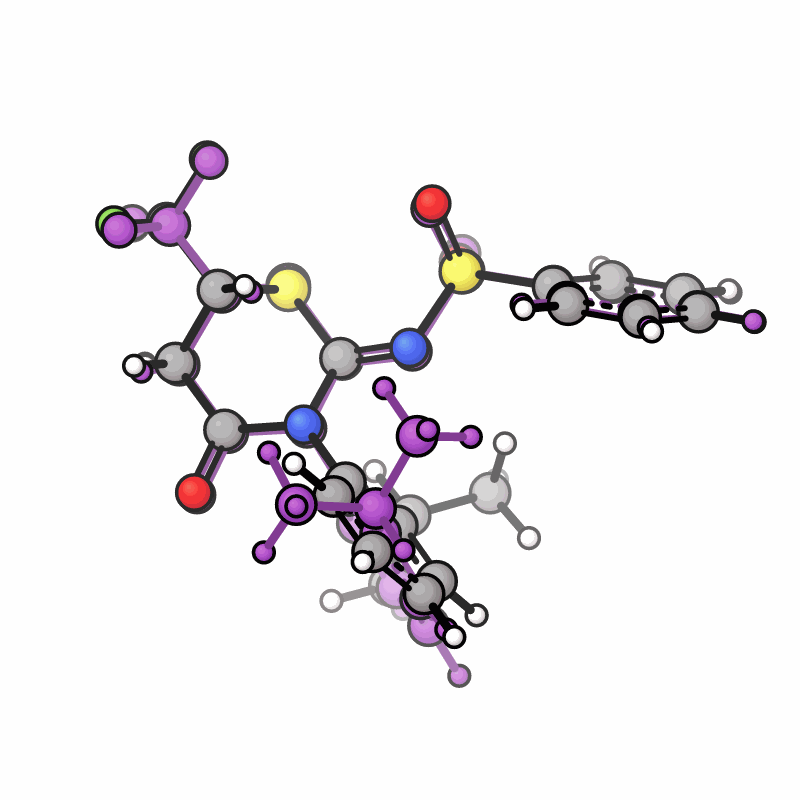

In [7]:
atrop_reactant_smiles = """[N:1](=[C:2]1/[S:3][C@@:4]([H:20])([C:21]([F:22])([F:23])[F:24])[C:5]([H:18])([H:19])[C:13](=[O:14])[N:6]1[c:7]1[c:8]([C:26]([H:27])([C:28]([H:29])([H:30])[H:31])[C:32]([H:33])([H:34])[H:35])[c:9]([H:15])[c:10]([H:25])[c:11]([H:16])[c:12]1[H:17])/[S:36](=[O:37])(=[O:38])[c:39]1[c:40]([H:43])[c:42]([H:47])[c:46]([H:49])[c:44]([H:48])[c:41]1[H:45] |wU:14.14|"""
atrop_product_smiles = """[N:1](=[C:2]1/[S:3][C@@:4]([H:20])([C:21]([F:22])([F:23])[F:24])[C:5]([H:18])([H:19])[C:13](=[O:14])[N:6]1[c:7]1[c:8]([C:26]([H:27])([C:28]([H:29])([H:30])[H:31])[C:32]([H:33])([H:34])[H:35])[c:9]([H:15])[c:10]([H:25])[c:11]([H:16])[c:12]1[H:17])/[S:36](=[O:37])(=[O:38])[c:39]1[c:40]([H:43])[c:42]([H:47])[c:46]([H:49])[c:44]([H:48])[c:41]1[H:45] |wU:14.13|"""
print(f"Reactant: {atrop_reactant_smiles}\nProduct:  {atrop_product_smiles}")

atrop_reactant = rx.parse_smiles(atrop_reactant_smiles, remove_hs=False)
atrop_product = rx.parse_smiles(atrop_product_smiles, remove_hs=False)
atrop_pair = rx.coembed(
    atrop_reactant,
    atrop_product,
    n=1,
    seed=1,
    charge=0,
)
print(f"Accepted pairs: {len(atrop_pair)}")

atrop_reactant_mol, atrop_product_mol = atrop_pair[0]
atrop_reactant_scene = xyzrender.load(atrop_reactant_mol)
atrop_product_scene = xyzrender.load(atrop_product_mol)
display(
    xyzrender.render_gif(
        atrop_reactant_scene,
        gif_rot=True,
        overlay=atrop_product_scene,
        auto_align=False,
        rot_frames=36,
        gif_fps=8,
        hy=True,
    )
)
